## Climate Hazard Dataset Exploration

#### Heat Hazard Dataset Exploration & Selection

**Project:** AI-Powered Climate Risk Intelligence Platform for Multi-Sector Decision Support in Germany

**Notebook:** 04_climate_dataset_exploration_heat_proxy_heatwave_days.ipynb

**Dataset:** Heat Waves Climatological

**Description:** This dataset represents annual climatological heat wave conditions across European NUTS-2 regions derived from reanalysis data. It provides a consistent measure of heat wave occurrence and intensity suitable for regional climate risk assessment.

**Purpose:** Selected as the heat hazard proxy for the AI-Powered Climate & ESG Risk Intelligence Platform because it provides a standardized measure of extreme heat conditions across Germany.

**Hazard type:** Extreme heat / heat wave proxy

**Spatial focus:** Germany

**Temporal focus:** 1990–2025

**Objective**

To explore, evaluate, and preprocess the Heat Waves Climatological dataset for Germany and determine its suitability as a heat hazard proxy within the AI-Powered Climate & ESG Risk Intelligence Platform.

This notebook documents dataset characteristics, quality assessment, preprocessing decisions, visualization, and preparation for integration into the master climate hazard database.

### Import Libraries

In [1]:
# =====================================================
# Climate Risk Intelligence Germany
# Dataset Exploration 04
# Dataset: Heat Waves Climatological
# Variable: to be confirmed after dataset inspection
# Hazard Proxy: Extreme Heat / Heat Waves
# Author: Purity Mbaabu
# =====================================================

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

### Locate Dataset

In [2]:
# =====================================================
# Locate NetCDF dataset
# =====================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

heat_file = (
    PROJECT_ROOT
    / "data"
    / "incoming"
    / "climate"
    / "09_heat_waves_climatological-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc"
)

print(heat_file)
print(heat_file.exists())

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\incoming\climate\09_heat_waves_climatological-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc
True


### Load Dataset

In [3]:
# =====================================================
# Load NetCDF dataset
# =====================================================

ds_heat = xr.open_dataset(heat_file)

ds_heat

<xarray.Dataset> Size: 237kB
Dimensions:                       (nuts: 340, time: 86)
Coordinates:
  * nuts                          (nuts) object 3kB 'ITC4' 'ITF1' ... 'UKI6'
  * time                          (time) datetime64[ns] 688B 1940-01-01 ... 2...
    realization                   int64 8B ...
    quantile                      float64 8B ...
Data variables:
    climatological_heatwave_days  (nuts, time) float64 234kB ...
Attributes:
    NCO:      netCDF Operators version 5.3.6 (Homepage = http://nco.sf.net, C...
    history:  Tue Jan 13 15:37:37 2026: /private/miniforge3/envs/ecde-data-de...

### Inspect Dataset

##### Step 1. Explore the variable

In [4]:
# =======================================================
# Inspect available variables
# =======================================================

list(ds_heat.data_vars)

['climatological_heatwave_days']

##### Step 2. Explore the variable metadata

In [5]:
# =======================================================
# Inspect variable metadata
# =======================================================

ds_heat["climatological_heatwave_days"].attrs

{'reduce_dims': ['lat', 'lon'],
 'comment': 'derived from 3 hourly ERA5 reanalysis',
 'units': 'day'}

##### Step 3. Look at actual values

In [6]:
# =======================================================
# Inspect variable values
# =======================================================

ds_heat["climatological_heatwave_days"]

<xarray.DataArray 'climatological_heatwave_days' (nuts: 340, time: 86)> Size: 234kB
[29240 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 3kB 'ITC4' 'ITF1' 'ITF2' ... 'UKI4' 'UKI5' 'UKI6'
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Step 4. Summary statistics

In [7]:
# ==============================================
# Generate summary statistics
# ==============================================

heat = ds_heat["climatological_heatwave_days"]

print(f"Minimum           : {heat.min().values:.3f}")
print(f"Maximum           : {heat.max().values:.3f}")
print(f"Mean              : {heat.mean().values:.3f}")
print(f"Standard Deviation: {heat.std().values:.3f}")

Minimum           : 0.000
Maximum           : 16.879
Mean              : 0.390
Standard Deviation: 1.280


##### Step 5. Missing values

In [8]:

# ==============================================
# Check missing values
# ==============================================

missing_values = heat.isnull().sum()

print(f"Missing values: {missing_values.values}")

Missing values: 516


##### Step 6. Inspect one region

In [9]:
# =======================================================
# Inspect one region
# =======================================================

heat.isel(nuts=0)

<xarray.DataArray 'climatological_heatwave_days' (time: 86)> Size: 688B
array([0.      , 0.      , 0.      , 0.411032, 0.      , 0.      , 0.      ,
       0.587683, 0.      , 0.      , 0.      , 0.      , 0.840633, 0.      ,
       0.      , 0.      , 0.      , 1.216727, 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.13539 ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 2.187224, 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.226056, 0.      ,
       0.      , 0.      , 1.771262, 0.      , 0.      , 0.      , 0.      ,
       7.289056, 0.      , 0.224628, 1.485795, 1.096623, 0.      , 0.      ,
       0.04472 , 1.051818, 1.723075, 1.016615, 0.      , 2.844422, 0.04472 ,
       2.944955, 0.134777, 2.080888, 0.225241, 0.076898, 2.62054 , 4.587878,
       0.934754, 2.583068])
Coordinates:
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
    nuts         <U4 16B 'ITC4'
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

### Dataset Quality Assessment

check out for:
1. Missing values
2. Negative values
3. Duplicate regions
4. Outliers

In [10]:
# ============================================
# Count total missing values
# ============================================

heat.isnull().sum()

<xarray.DataArray 'climatological_heatwave_days' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

**Step 1.1 Missing Values by Region**

In [11]:
# =======================================================
# Count missing values by region
# =======================================================

missing_by_region = heat.isnull().sum(dim="time")

missing_by_region_df = (
    missing_by_region
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_by_region_df

,nuts,realization,quantile,missing_values
0,ITC4,0,0.99,0
1,ITF1,0,0.99,0
2,ITF2,0,0.99,0
3,ITF3,0,0.99,0
4,ITF4,0,0.99,0
...,...,...,...,...
335,UKH3,0,0.99,0
336,UKI3,0,0.99,0
337,UKI4,0,0.99,0
338,UKI5,0,0.99,0


**Step 1.2 Missing Values by Year**


In [12]:
# =======================================================
# Count missing values by year
# =======================================================

missing_years = heat.isnull().sum(dim="nuts")

missing_years_df = (
    missing_years
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_years_df

,time,realization,quantile,missing_values
0,1940-01-01,0,0.99,6
1,1941-01-01,0,0.99,6
2,1942-01-01,0,0.99,6
3,1943-01-01,0,0.99,6
4,1944-01-01,0,0.99,6
...,...,...,...,...
81,2021-01-01,0,0.99,6
82,2022-01-01,0,0.99,6
83,2023-01-01,0,0.99,6
84,2024-01-01,0,0.99,6


##### Inspect the regions with missing values.

The following NUTS-2 regions contain missing observations:

In [13]:
# =====================================================
# Step 1.1: Missing Values by Region
# =====================================================

# Count missing values for each region
missing_by_region = heat.isnull().sum(dim="time")

# Keep only regions with missing values
missing_regions = missing_by_region.where(
    missing_by_region > 0,
    drop=True
)

# Convert to table
missing_regions_df = (
    missing_regions
    .to_dataframe(name="Missing_Years")
    .reset_index()
)

display(missing_regions_df)

,nuts,realization,quantile,Missing_Years
0,PT20,0,0.99,86.0
1,FRY1,0,0.99,86.0
2,FRY2,0,0.99,86.0
3,FRY3,0,0.99,86.0
4,FRY4,0,0.99,86.0
5,FRY5,0,0.99,86.0


**Summary**

- Missing values limited to six overseas NUTS-2 regions
- 334 mainland NUTS-2 regions have complete records
- Suitable for climate risk modelling

##### Overall Percentage Missing

In [14]:
# ============================================
# Percentage of missing values
# ============================================

total_cells = heat.size

missing_cells = heat.isnull().sum().values

percentage_missing = (missing_cells / total_cells) * 100

print(f"Total observations : {total_cells}")
print(f"Missing values     : {missing_cells}")
print(f"Missing (%)        : {percentage_missing:.2f}%")

Total observations : 29240
Missing values     : 516
Missing (%)        : 1.76%


##### Negative Values

In [15]:
# ============================================
# Check for negative values
# ============================================

negative_values = (heat < 0).sum()

print(f"Negative values: {negative_values.values}")

Negative values: 0


##### Duplicate Regions

In [16]:
# ============================================
# Check duplicate NUTS regions
# ============================================

nuts_codes = ds_heat.coords["nuts"].values

print("Total NUTS regions :", len(nuts_codes))
print("Unique NUTS regions:", len(set(nuts_codes)))

Total NUTS regions : 340
Unique NUTS regions: 340


##### Outliers

In [17]:
# ============================================
# Distribution percentiles
# ============================================

heat.quantile(
    [0,
     0.25,
     0.50,
     0.75,
     0.95,
     0.99,
     1.00]
)

<xarray.DataArray 'climatological_heatwave_days' (quantile: 7)> Size: 56B
array([ 0.        ,  0.        ,  0.        ,  0.        ,  2.81702426,
        6.74533046, 16.87868598])
Coordinates:
  * quantile  (quantile) float64 56B 0.0 0.25 0.5 0.75 0.95 0.99 1.0
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

##### Quality Assessment Summary

- 1.76% missing values limited to six overseas NUTS-2 regions
- No negative values detected
- No duplicate NUTS-2 identifiers
- Values represent realistic climatological heatwave day ranges
- Dataset passes all key quality checks

### Suitability Assessment

##### Step 1. Temporal Suitability

In [18]:
# =======================================================
# Check temporal coverage
# =======================================================

start_year = str(ds_heat.time.min().values)[:10]
end_year = str(ds_heat.time.max().values)[:10]
number_of_years = ds_heat.sizes["time"]

print(f"Start Year       : {start_year}")
print(f"End Year         : {end_year}")
print(f"Total Years      : {number_of_years}")

Start Year       : 1940-01-01
End Year         : 2025-01-01
Total Years      : 86


**Summary**

• Coverage: 1940–2025

• Annual observations

• Suitable for long-term climate analysis

##### Step 2. Spatial Suitability

In [19]:
# ==========================================================
# check Spatial Coverage
# ==========================================================

print(f"Total NUTS-2 regions : {ds_heat.sizes['nuts']}")

Total NUTS-2 regions : 340


**Summary**

- 340 NUTS-2 regions
- Consistent spatial coverage
- Suitable for regional climate assessment

##### Step 3. Variable Suitability


- Variable: climatological_heatwave_days
- Represents the annual climatological number of heatwave days
- Appropriate heat hazard proxy for climate risk modelling

##### Step 4. Data Completeness

- 1.76% missing values
- Missing values confined to six overseas NUTS-2 regions
- Mainland Europe has complete coverage
- Suitable for downstream modelling after filtering to Germany

##### Step 5. Integration Compatibility

- Standardized NUTS-2 regional identifiers
- Annual temporal resolution
- Compatible with additional climate, exposure, and vulnerability datasets
- Suitable for master climate hazard database integration

### Dataset Selection Decision

##### Overall Suitability Assessment

✅ Selected

- Long temporal coverage
- Complete spatial coverage
- High data quality
- Suitable heat hazard indicator
- Compatible with master climate database

### Extract German NUTS-2 regions for 1990-2025

**Germany Subsetting**

Prepare the dataset for model development by extracting German NUTS-2 regions and restricting the analysis period to 1990–2025.

In [20]:
# =======================================================
# Extract German NUTS-2 subset (1990–2025)
# =======================================================

german_nuts = [
    code for code in heat["nuts"].values
    if str(code).startswith("DE")
]

# Subset Germany and project time period
germany_heat = heat.sel(
    nuts=german_nuts,
    time=slice("1990-01-01", "2025-01-01")
)

print(f"Number of German NUTS-2 regions: {len(german_nuts)}")
print(f"Start year: {str(germany_heat.time.min().values)[:10]}")
print(f"End year  : {str(germany_heat.time.max().values)[:10]}")
print(f"Shape     : {germany_heat.shape}")

germany_heat

Number of German NUTS-2 regions: 38
Start year: 1990-01-01
End year  : 2025-01-01
Shape     : (38, 36)


<xarray.DataArray 'climatological_heatwave_days' (nuts: 38, time: 36)> Size: 11kB
array([[0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.585835],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.602347],
       [0.      , 0.      , 0.      , ..., 0.887822, 0.      , 0.526868],
       ...,
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 0.190471],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 0.      ],
       [0.      , 0.      , 0.      , ..., 0.      , 0.      , 1.794337]],
      shape=(38, 36))
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

- Germany successfully extracted
- NUTS-2 regions only
- Project period: 1990–2025
- Ready for visualization

### Save the Germany Heat Proxy Dataset

In [21]:
# =======================================================
# Save Germany heat proxy dataset
# =======================================================

germany_raw_dir = PROJECT_ROOT / "data" / "raw" / "climate" / "germany"
germany_raw_dir.mkdir(parents=True, exist_ok=True)

germany_heat_file = germany_raw_dir / "heatwave_days_germany_nuts2_1990_2025.nc"

germany_heat.to_netcdf(germany_heat_file)

print("Saved Germany heat proxy dataset to:")
print(germany_heat_file)
print(f"File exists: {germany_heat_file.exists()}")

# =======================================================
# Verify saved dataset
# =======================================================

germany_heat_check = xr.open_dataarray(germany_heat_file)

germany_heat_check

Saved Germany heat proxy dataset to:
d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\raw\climate\germany\heatwave_days_germany_nuts2_1990_2025.nc
File exists: True


<xarray.DataArray 'climatological_heatwave_days' (nuts: 38, time: 36)> Size: 11kB
[1368 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
    quantile     float64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    comment:      derived from 3 hourly ERA5 reanalysis
    units:        day

### Visualization

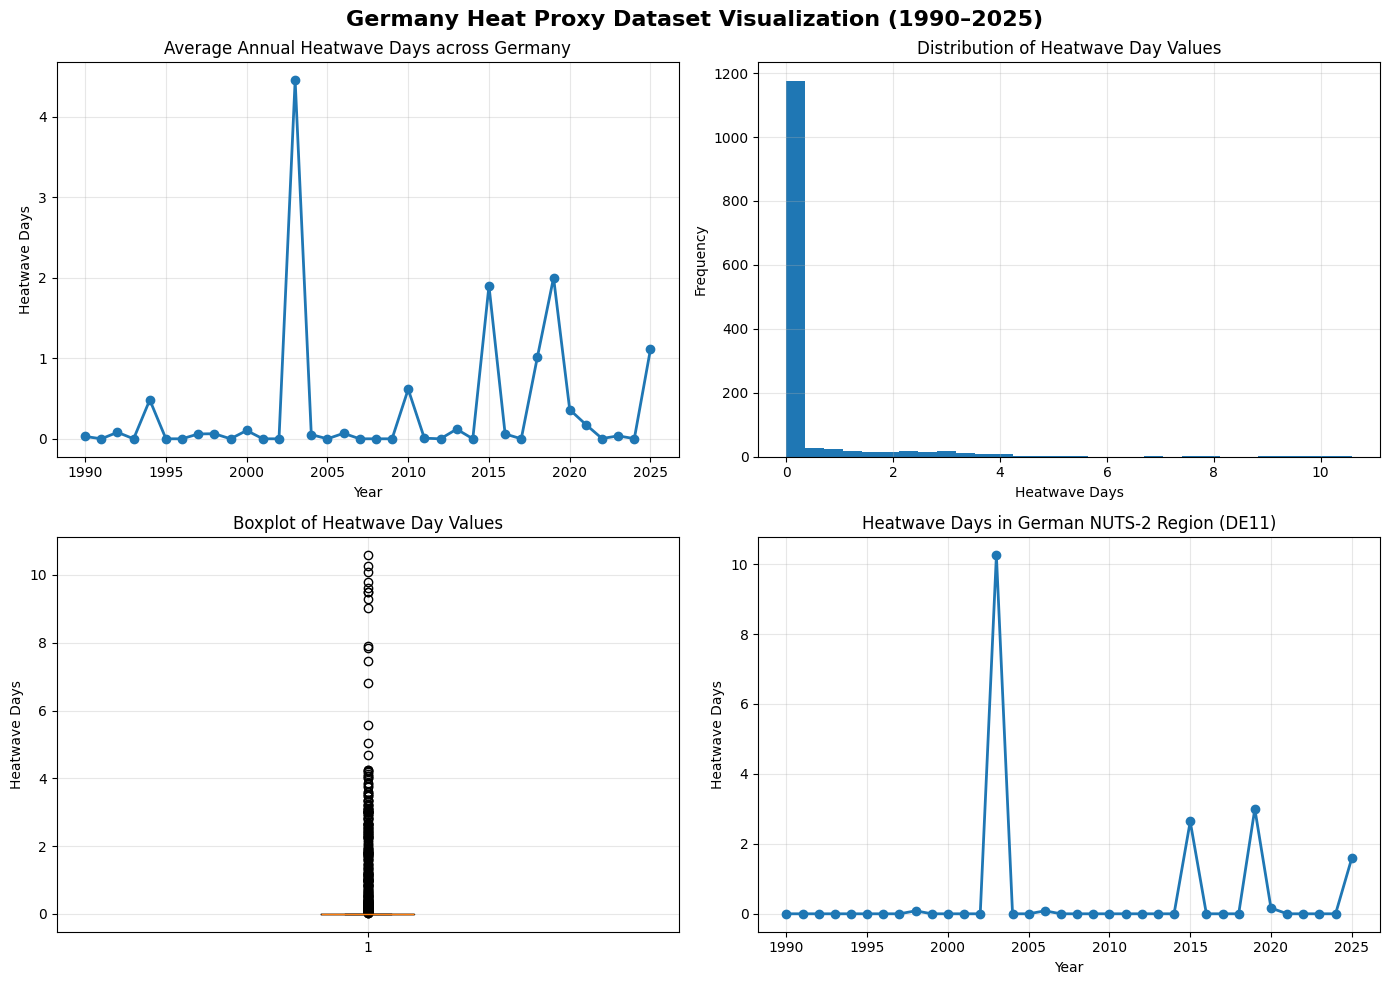

In [22]:
# =====================================================
# Visualize Germany heat proxy dataset (1990–2025)
# Four plots in one 2x2 canvas
# =====================================================

# Prepare data
germany_heat_mean = germany_heat.mean(dim="nuts")

values = germany_heat.values.flatten()
values = values[~np.isnan(values)]

example_region = (
    "DE11"
    if "DE11" in germany_heat["nuts"].values
    else germany_heat["nuts"].values[0]
)

region_heat = germany_heat.sel(nuts=example_region)

# Create 2x2 plot canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average annual heatwave days across Germany
axes[0, 0].plot(
    germany_heat_mean["time"].dt.year,
    germany_heat_mean,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Average Annual Heatwave Days across Germany")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Heatwave Days")
axes[0, 0].grid(alpha=0.3)

# 2. Distribution of heatwave day values
axes[0, 1].hist(
    values,
    bins=30
)
axes[0, 1].set_title("Distribution of Heatwave Day Values")
axes[0, 1].set_xlabel("Heatwave Days")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# 3. Boxplot of heatwave day values
axes[1, 0].boxplot(values)
axes[1, 0].set_title("Boxplot of Heatwave Day Values")
axes[1, 0].set_ylabel("Heatwave Days")
axes[1, 0].grid(alpha=0.3)

# 4. Example German NUTS-2 region
axes[1, 1].plot(
    region_heat["time"].dt.year,
    region_heat,
    marker="o",
    linewidth=2
)
axes[1, 1].set_title(f"Heatwave Days in German NUTS-2 Region ({example_region})")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Heatwave Days")
axes[1, 1].grid(alpha=0.3)

# Overall title and layout
fig.suptitle(
    "Germany Heat Proxy Dataset Visualization (1990–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Visualization Summary


The exploratory visualizations confirm that:

- Climatological heatwave days exhibit substantial interannual variability across Germany (1990–2025).
- High heatwave-day years are relatively infrequent but clearly distinguishable.
- Regional differences among German NUTS-2 regions are well represented.
- The dataset provides a robust heat hazard proxy for AI-based climate risk modelling in Germany.

##### Implications for AI Model Development

The dataset will be retained in its original physical units within the raw data repository.

During feature engineering, this variable will be standardized together with the remaining climate hazard variables before training the Feed-Forward Neural Network (FFNN), while preserving the original dataset for reproducibility.

##### Next Processing Step

The Germany subset (1990–2025) has been successfully extracted.

Remaining workflow:

- Merge all climate variables into a master dataset.
- Perform feature engineering and standardization.
- Build the AI-ready modelling dataset.
- Train and evaluate the Feed-Forward Neural Network (FFNN).